## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.00262ms.
00: Found the following number of samples per ticker: SPX: 2616.
00: Found date range 2015-01-02 to 2025-07-01 with 2616 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2078 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.34s.
/done


In [2]:
sampler.features

{'ask_vol',
 'bdte',
 'bid_vol',
 'call_ask',
 'call_bid',
 'call_opt_id',
 'df',
 'expiry_id',
 'fit1_vol',
 'fitX_vol',
 'fwd',
 'fwd_ref',
 'is_am',
 'is_american',
 'is_valid',
 'log_open_interest',
 'log_volume',
 'mask_arb_free',
 'mkt_call_ask',
 'mkt_call_bid',
 'mkt_call_log_open_interest',
 'mkt_call_log_volume',
 'mkt_put_ask',
 'mkt_put_bid',
 'mkt_put_log_open_interest',
 'mkt_put_log_volume',
 'nms',
 'nms_atm',
 'pure_ask_delta',
 'pure_ask_dk',
 'pure_ask_gamma',
 'pure_ask_price',
 'pure_ask_theta',
 'pure_ask_vega',
 'pure_bid_delta',
 'pure_bid_dk',
 'pure_bid_gamma',
 'pure_bid_price',
 'pure_bid_theta',
 'pure_bid_vega',
 'pure_fit1_delta',
 'pure_fit1_dk',
 'pure_fit1_gamma',
 'pure_fit1_price',
 'pure_fit1_theta',
 'pure_fit1_vega',
 'pure_fitX_delta',
 'pure_fitX_dk',
 'pure_fitX_gamma',
 'pure_fitX_price',
 'pure_fitX_theta',
 'pure_fitX_vega',
 'pure_strike',
 'put_opt_id',
 'spot_prev',
 'spot_ref',
 'spot_ret',
 'strike',
 'time_y',
 'tte_y'}

## AEC

Cleaning up memory... done.
['ask_vol', 'bdte', 'bid_vol', 'call_ask', 'call_bid', 'call_opt_id', 'df', 'expiry_id', 'fit1_vol', 'fitX_vol', 'fwd', 'fwd_ref', 'is_am', 'is_american', 'is_valid', 'log_open_interest', 'log_volume', 'mask_arb_free', 'mkt_call_ask', 'mkt_call_bid', 'mkt_call_log_open_interest', 'mkt_call_log_volume', 'mkt_put_ask', 'mkt_put_bid', 'mkt_put_log_open_interest', 'mkt_put_log_volume', 'nms', 'nms_atm', 'pure_ask_delta', 'pure_ask_dk', 'pure_ask_gamma', 'pure_ask_price', 'pure_ask_theta', 'pure_ask_vega', 'pure_bid_delta', 'pure_bid_dk', 'pure_bid_gamma', 'pure_bid_price', 'pure_bid_theta', 'pure_bid_vega', 'pure_fit1_delta', 'pure_fit1_dk', 'pure_fit1_gamma', 'pure_fit1_price', 'pure_fit1_theta', 'pure_fit1_vega', 'pure_fitX_delta', 'pure_fitX_dk', 'pure_fitX_gamma', 'pure_fitX_price', 'pure_fitX_theta', 'pure_fitX_vega', 'pure_strike', 'put_opt_id', 'spot_prev', 'spot_ref', 'spot_ret', 'strike', 'time_y', 'tte_y']
['ask_vol', 'bdte', 'bid_vol', 'call_ask', 'ca

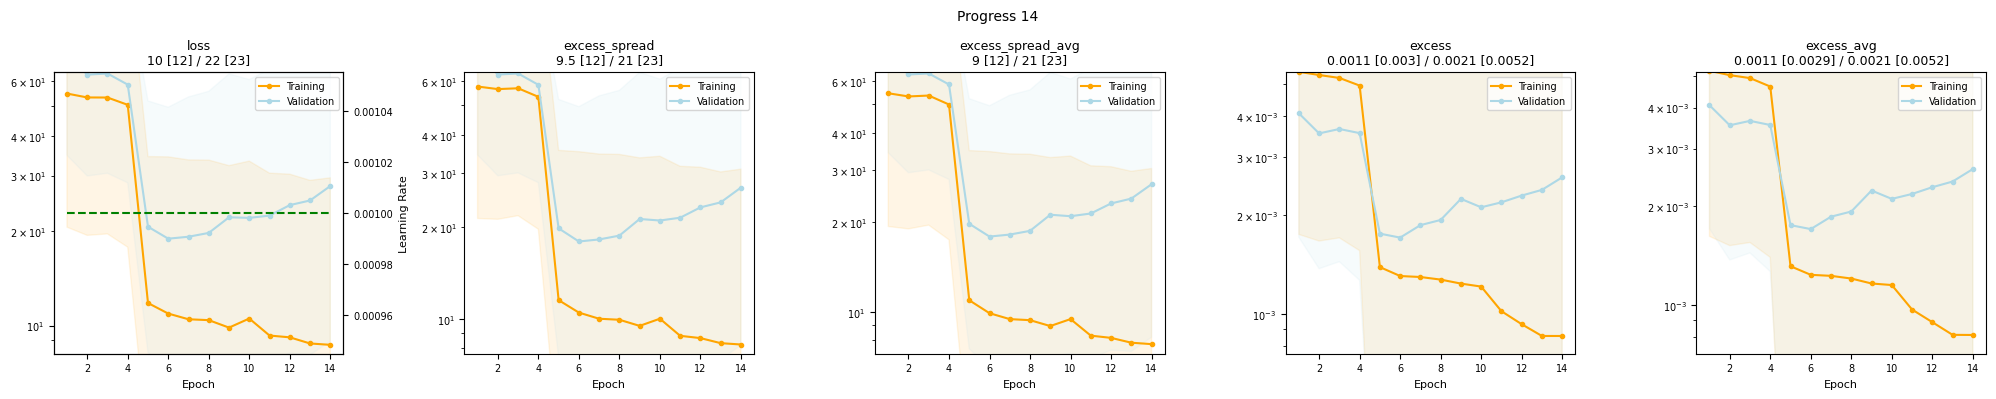

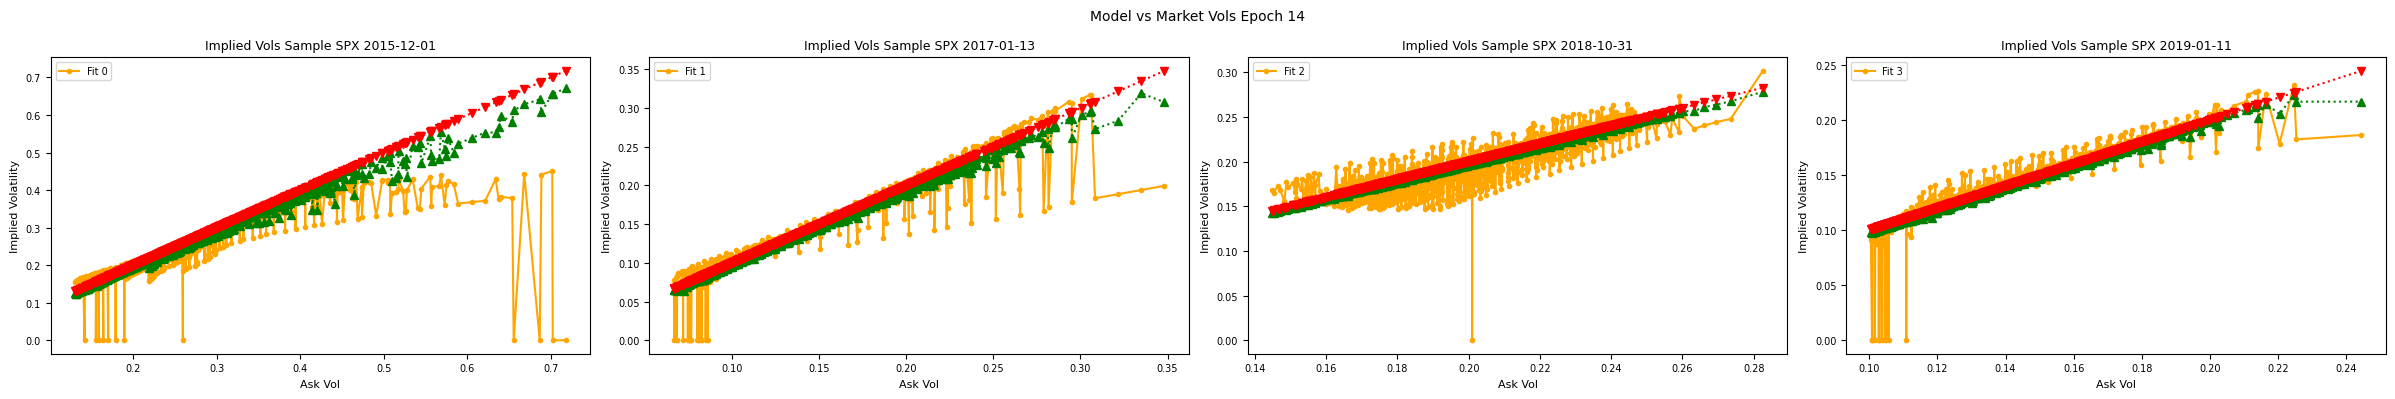

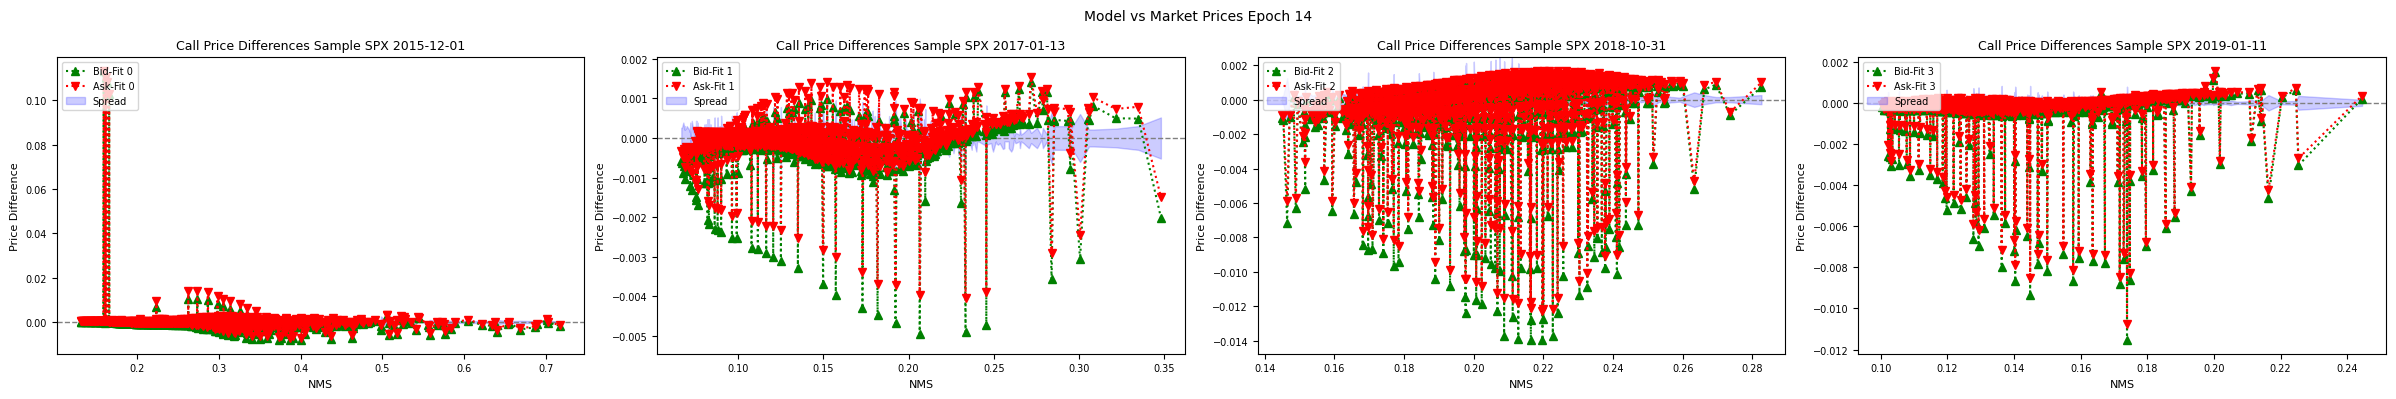

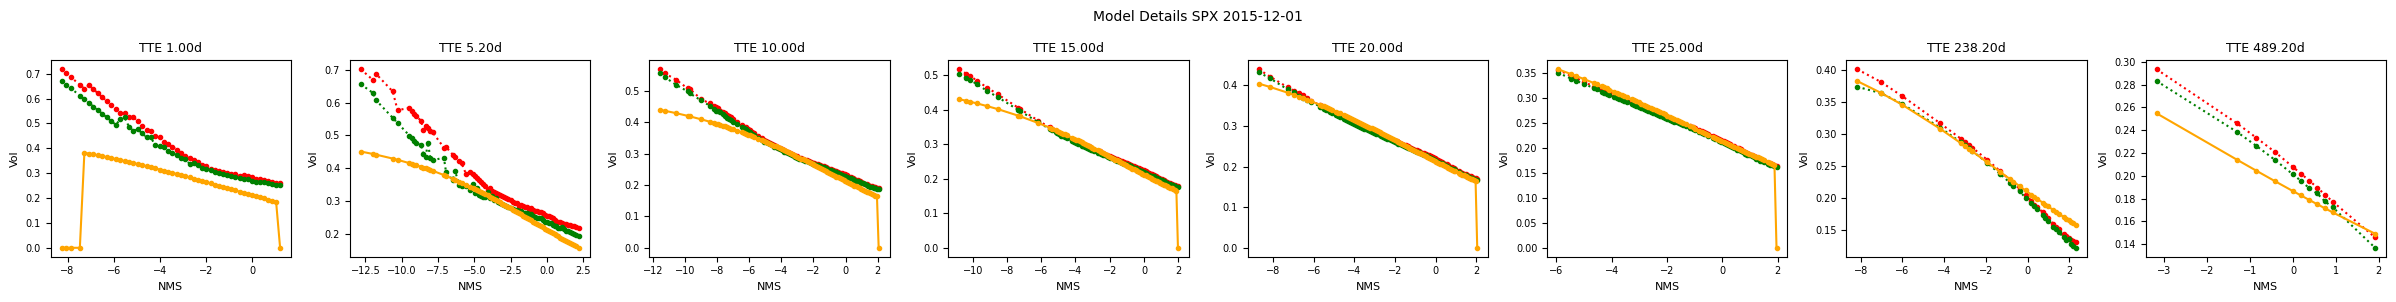

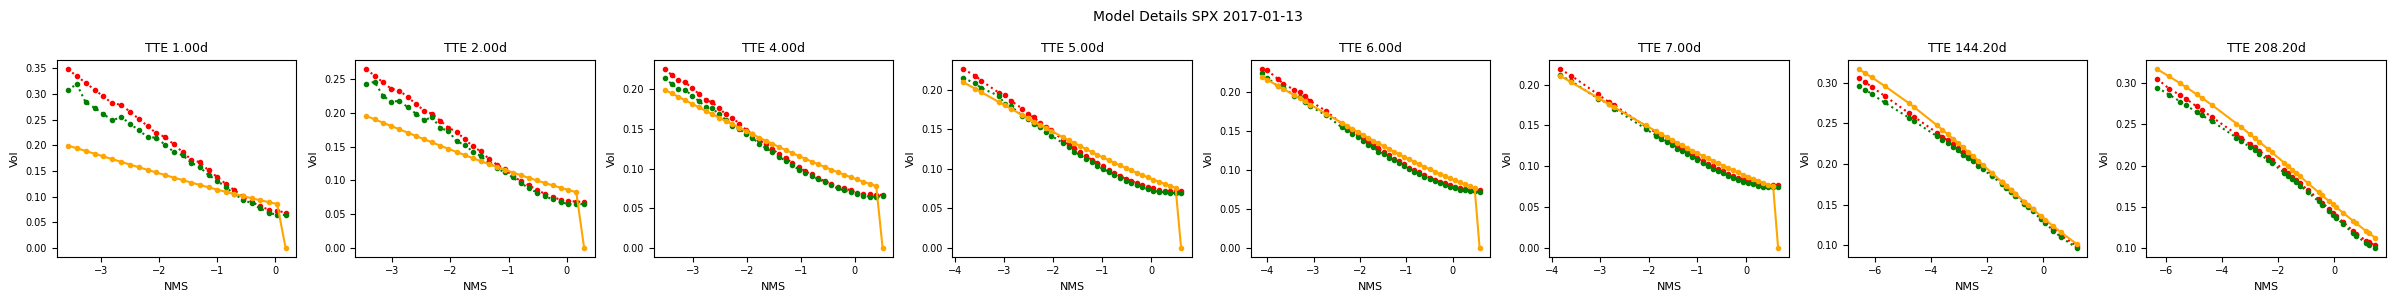

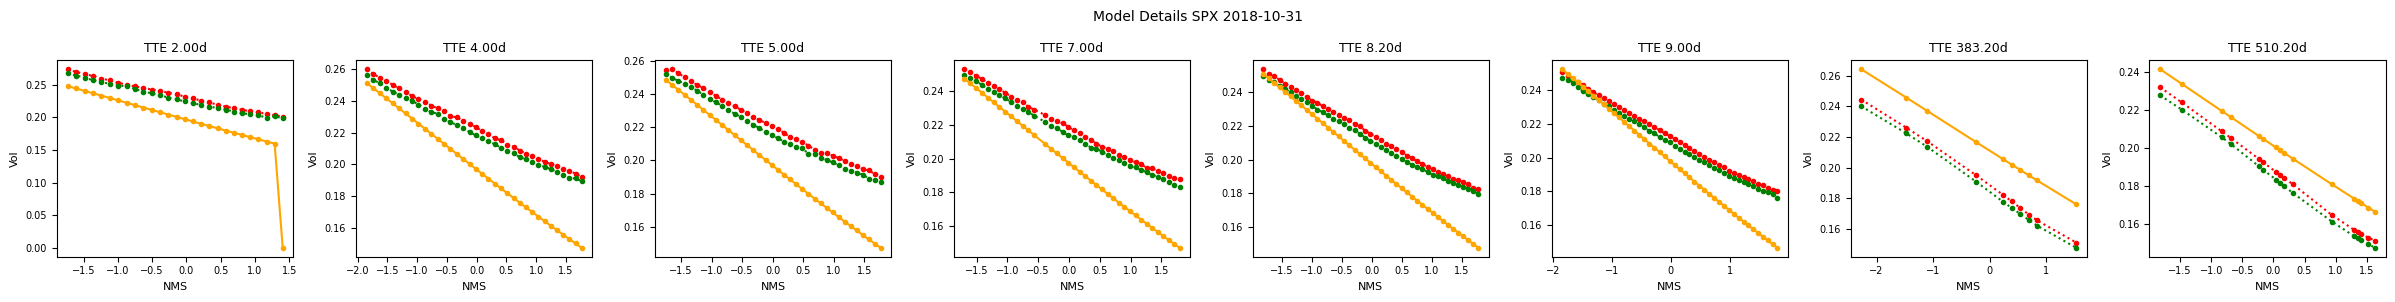

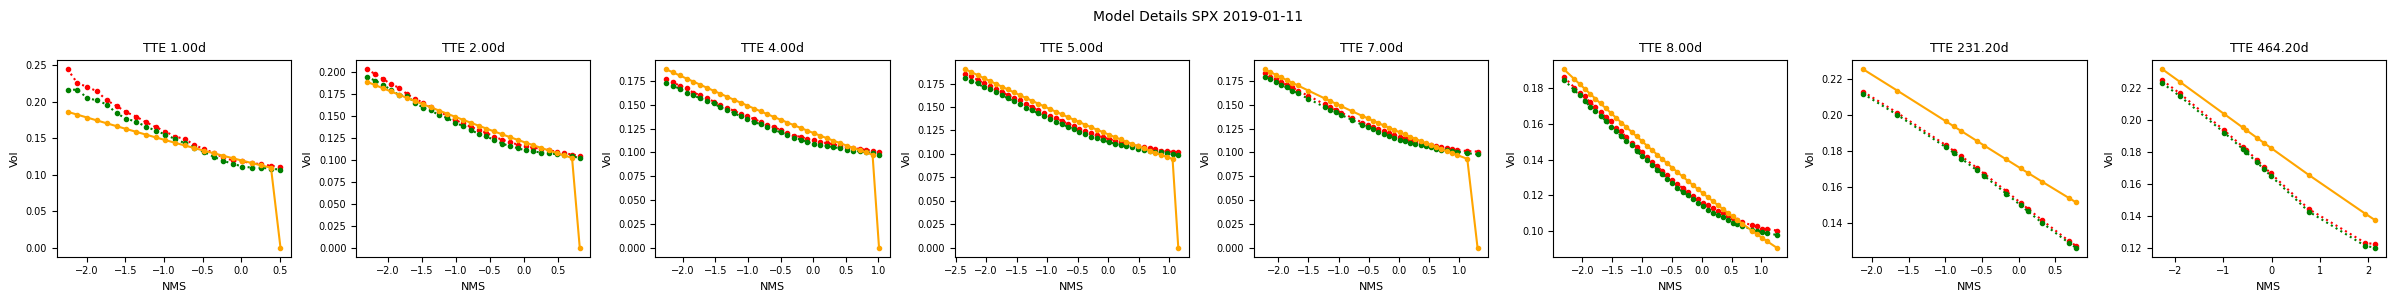

00: Training 'train_vol_vol_actatt-big' epoch 2/1000 error avg trn 51.19; val 53.16/62.83 [4:10 1.2s 0.31s]. LR: 1.00e-03, GN 19.42, excess_weighted: 0.003606/0.002835, excess_weighted_avg: 0.003707/0.002993, excess_spread: 56.5/63.06, excess_spread_avg: 53.19/63.08, excess: 0.005312/0.003533, excess_avg: 0.005022/0.003533. ETA: 71:01:02.
01:   Epoch 2: Saving new best validation loss 62.83 vs. 72.93 at epoch 1 to '/media/storage/quantdata/experiments/dysanos/simple/32536c2da5702cb9/v1/train_vol_vol_actatt-big ff89080a/best.pt'... done; this took 0.052s.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/32536c2da5702cb9/v1/train_vol_vol_actatt-big ff89080a/last.pt... done; this took 0.031s.
00: Training 'train_vol_vol_actatt-big' epoch 3/1000 error avg trn 46.98; val 53.13/63.36 [6:15 1.2s 0.31s]. LR: 1.00e-03, GN 20.51, excess_weighted: 0.003628/0.002858, excess_weighted_avg: 0.003706/0.003004, excess_spread: 56.85/63.56, excess_spread_avg: 53.56/63.59, ex

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    encoder = LatentAttentionEncoderFactory(
        num_head = 64,
        num_QK = 16,
        num_latent = 16,
        KV_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 128, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 3,
            num_width = 128,
            activation = 'Softplus',    
        )
    )
)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.3", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, debug=False, val_batch_size=128 )


In [ ]:

@dataclass(frozen=True)
class A:
    a = 1

    def f(self):
        self.__dict__['c'] = 1
a = A()
a.f()
a.c